# Map flux
## Make the same maps as the one presented in https://arxiv.org/pdf/2104.06855.pdf

### Import modules

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap
import pandas as pd
from scipy.interpolate import interp1d

/home/tomas/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### User parameters

In [2]:
incl = 48 * np.pi / 180.0
Nx = 32
f_Ny = 0.15 # Nyquist frequency (< 0.6)
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

### Define some constants

In [3]:
M_BH = 5.5e7 #             !Black hole mass [Msun]
R_g = 1.477e5*M_BH

h = 6.6260755e-27
k_B = 1.380658e-16
m_e = 9.10938e-28
c = 2.99792458e10
e = 4.8032068e-10
kpc = 3.0856e21  #Kpc a cm
distance = 3.8e3  #Distancia al objeto en kpc
convert = 206265e3/(distance*kpc) # image to angular size (mas)
# flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

In [4]:
R_g

8123500000000.0

### Define some useful functions

In [5]:
def safe_log(x):
    return np.where(x > 0, np.log(x), -300)

#### Obtenemos la emisividad y absorcion para cada z

In [6]:
def get_j_alpha(nu, delta, filename='./../Code/Em_Abs.dat'):
    # Read the data from the file
    data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
    
    # Find the energy associated with the given frequency nu
    energy_nu = h * nu * 1e9  # Convert frequency to energy
    
    # Filter the data for each z_value
    filtered_data = []
    for z in data["z_value"].unique():
        z_data = data[data["z_value"] == z]
        closest_index = (np.abs(z_data["energy"] - energy_nu/delta[z-1])).idxmin()
        filtered_data.append(z_data.loc[closest_index, ["energy", "emisivity", "absorption"]])

    # Combine the filtered data into a DataFrame
    filtered_data = pd.DataFrame(filtered_data)
    return filtered_data['emisivity'], filtered_data['absorption']

#### Obtenemos los valores de las cantidades que varian con z

In [7]:
def get_z_rz(filename='./../Code/quant_FF.dat',filename2='./../Code/quant_FF_norm.dat'):
    """
    Load and return specific columns from the given file.

    Parameters:
        filename (str): Path to the file containing the data.

    Returns:
        tuple: Arrays of z, B, r_out, r_in, and delta_obs values.
    """
    return np.loadtxt(filename, usecols=(0, 1, 2, 3, 5), unpack=True)

#### Funcion que calcula l(x,z)

In [8]:
def crossed_length(x, R_in, R_out):
        if abs(x) < abs(R_out) and abs(x) > abs(R_in):
                l = 2.0 * np.sqrt(R_out**2 - x**2)
        elif abs(x) <= abs(R_in):
                l = 2.0 * (np.sqrt(R_out**2 - x**2) - np.sqrt(abs(R_in**2 - x**2)))
        else:
                l = 0.0
        return l

#### Calculamos el valor de la intensidad I(x,z)

In [9]:
#Esta interpola las funciones de z
def Intensity_import_interp(x_value, nu, z_value):
    '''
    Function that returns the intensity for a given frequency at a given range of z, determined by the length of the input array.
    The function uses the values of absoption and emissivity imported from the function get_j_alpha that are closest to the specified energy
    (given by nu) to calculate the intensity based on the input parameters.
    
    This function interpolates for any given value of z'''

    # Retrieve data
    if not hasattr(Intensity_import_interp, "_cached_data"):
        z, B, r_out, r_in, delta_obs = get_z_rz()
        delta_obs = np.sqrt(delta_obs)
        j, alpha = get_j_alpha(nu, delta_obs)
        Intensity_import_interp._cached_data = (z, B, r_out, r_in, delta_obs, j, alpha)
    else:
        z, B, r_out, r_in, delta_obs, j, alpha = Intensity_import_interp._cached_data
    j=j.to_numpy()
    alpha=alpha.to_numpy()
    # Precompute constants

    # Interpolations
    I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]
    term_exp_values = [alpha[idx] / delta_obs[idx] for idx in range(len(z))]
    # Remove NaN values from I_z_values and term_exp_values
    valid_indices = ~np.isnan(I_z_values) & ~np.isnan(term_exp_values)
    I_z_values = np.array(I_z_values)[valid_indices]
    term_exp_values = np.array(term_exp_values)[valid_indices]
    z2 = np.array(z)[valid_indices]

    I_z = interp1d(safe_log(z2), safe_log(I_z_values), bounds_error=False, fill_value='extrapolate')
    term_exp = interp1d(safe_log(z2), safe_log(term_exp_values), bounds_error=False, fill_value='extrapolate')
    r_out_interp = interp1d(safe_log(z), safe_log(r_out), bounds_error=False, fill_value='extrapolate')
    r_in_interp = interp1d(safe_log(z), safe_log(r_in), bounds_error=False, fill_value='extrapolate')

    # Compute intensity
    intensity_result = np.zeros(len(x_value))
    r_avg=0.5*(np.exp(r_out_interp(safe_log(z_value)))+np.exp(r_in_interp(safe_log(z_value))))
    tau_avg=crossed_length(r_avg, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
    for j, x in enumerate(x_value):
        tau = crossed_length(x, np.exp(r_in_interp(safe_log(z_value))), np.exp(r_out_interp(safe_log(z_value)))) * np.exp(term_exp(safe_log(z_value))) / np.sin(incl)
        intensity_result[j] = np.exp(I_z(safe_log(z_value))) * (-np.expm1(-tau)) #(1+tau)# opt thin #[erg/cm^2/s/erg/sr]
    

    return intensity_result*h, tau_avg #[erg/cm^2/s/Hz/sr]



In [10]:
z, _, r_out, _, _ = get_z_rz()
z = np.linspace(z.min(), z.max(), 200)
x = np.linspace(-r_out.max(), r_out.max(), 200)
#x = np.linspace(-r_out.max(), r_out.max(), 200)
# Create a meshgrid for plotting
X_m, Z_m = np.meshgrid(x, z)
I = np.zeros((len(z), len(x)))
tau_avg= np.zeros(len(z))
for i, z_value in enumerate(z):
    I[i], tau_avg[i]=Intensity_import_interp(x, 230.0, z_value) #[erg/cm^2/s/Hz/sr]

/tmp/ipykernel_15406/3843225759.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])
/tmp/ipykernel_15406/1768712390.py:23: RuntimeWarning: invalid value encountered in scalar divide
  I_z_values = [delta_obs[idx]**3 * j[idx] / alpha[idx] for idx in range(len(z))]


In [11]:
if hasattr(Intensity_import_interp, "_cached_data"):
    del Intensity_import_interp._cached_data

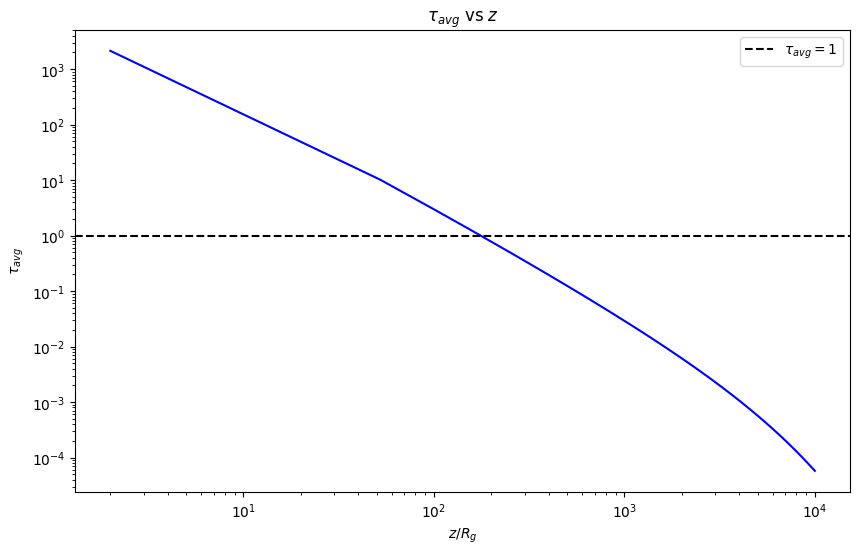

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(z/R_g, tau_avg, color='blue')
plt.axhline(y=1, color='black', linestyle='--', label=r'$\tau_{avg}=1$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$z/R_g$')
plt.ylabel(r'$\tau_{avg}$')
plt.title(r'$\tau_{avg}$ vs $z$')
plt.legend()
plt.show()

/tmp/ipykernel_15406/3843225759.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(filename, delim_whitespace=True, header=None, names=["energy", "emisivity", "absorption", "z_value"])


200


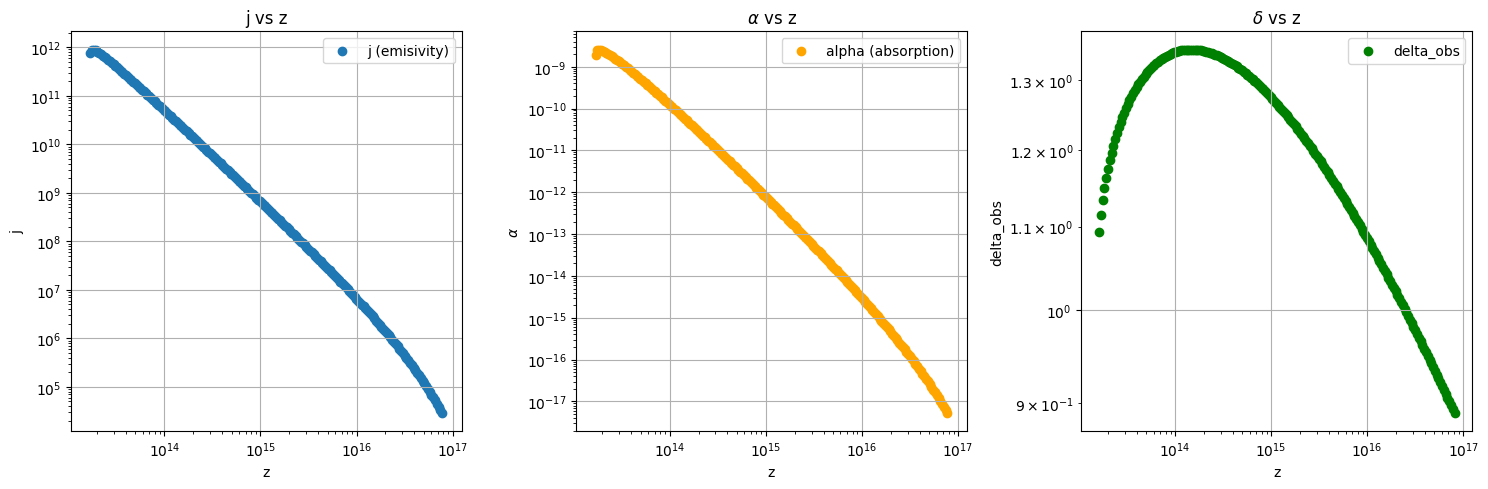

In [13]:
z, B, r_out, r_in, delta_obs = get_z_rz()
delta_obs = np.sqrt(delta_obs)
j, alpha = get_j_alpha(45.0, delta_obs)

plt.figure(figsize=(15, 5))
print(len(z))
# Plot j vs z
plt.subplot(1, 3, 1)
plt.scatter(z, j, label='j (emisivity)')
plt.xlabel('z')
plt.ylabel('j')
plt.xscale('log')
plt.yscale('log')
plt.title('j vs z')
plt.grid()
plt.legend()

# Plot alpha vs z
plt.subplot(1, 3, 2)
plt.scatter(z, alpha, label='alpha (absorption)', color='orange')
plt.xlabel('z')
plt.ylabel(r'$\alpha$')
plt.xscale('log')
plt.yscale('log')
plt.title(r'$\alpha$ vs z')
plt.grid()
plt.legend()

# Plot delta_obs vs z
plt.subplot(1, 3, 3)
plt.scatter(z, delta_obs, label='delta_obs', color='green')
plt.xlabel('z')
plt.ylabel('delta_obs')
plt.xscale('log')
plt.yscale('log')
plt.title(r'$\delta$ vs z')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

In [25]:
I.max()

np.float64(0.00036157322791145887)

0.0


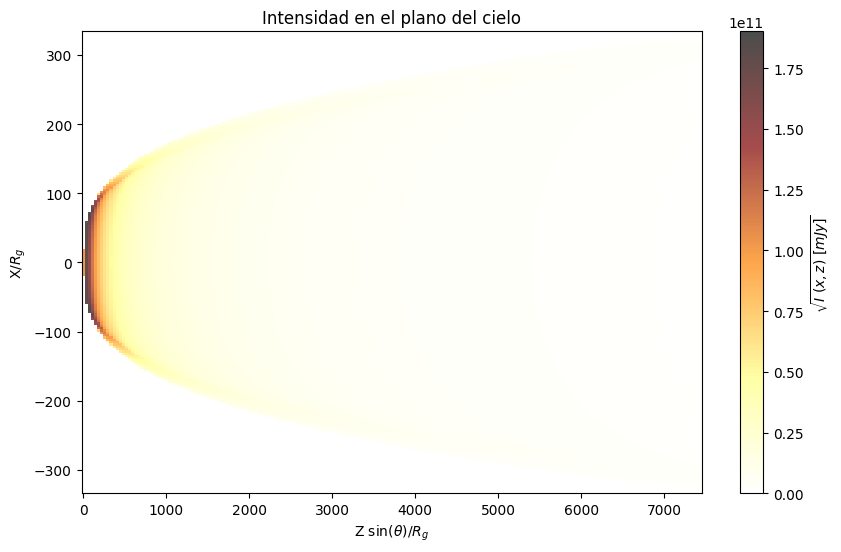

In [14]:
# Plotting
print(I.min())
palette = plt.cm.afmhot_r
plt.figure(figsize=(10, 6))
norm = matplotlib.colors.Normalize(vmin=0, vmax=np.sqrt(I.max()*1e26))
plt.pcolormesh(Z_m * np.sin(incl)/R_g, X_m/R_g, np.sqrt(I*1e26), cmap=palette, norm=norm, alpha=0.7)
#plt.pcolormesh(Z_m * np.sin(incl)/R_g, -X_m/R_g, I, cmap=palette, norm=norm, alpha=0.7)
#plt.pcolormesh(Z_m * np.sin(incl) * convert, X_m * convert, I, cmap=palette, alpha=0.7)
plt.colorbar(label=r'$\sqrt{I~(x,z)~[mJy]}$')
plt.xlabel(r'Z $\sin(\theta)$/$R_g$')
plt.ylabel(r'X/$R_g$')
#plt.xlim(0,100000)
plt.title(r'Intensidad en el plano del cielo')
plt.show()

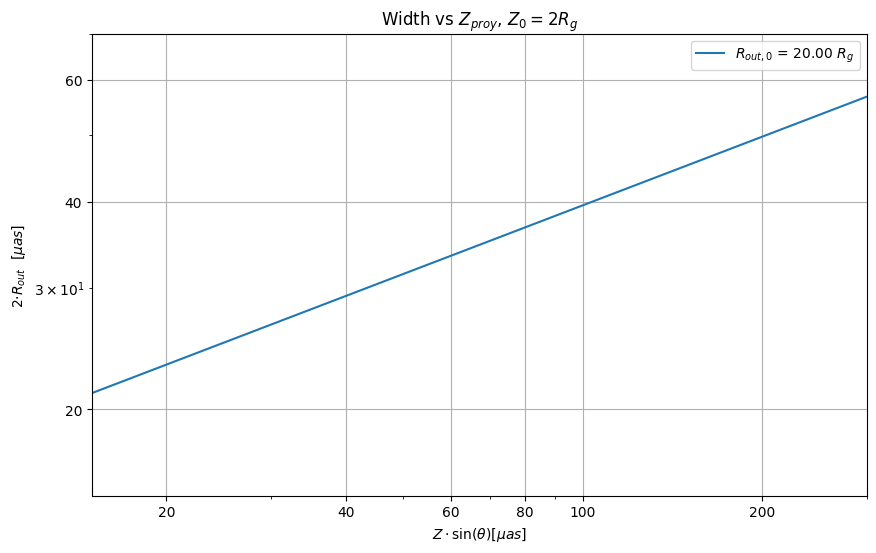

In [15]:
plt.figure(figsize=(10, 6))
# Plot the data
plt.plot(z*convert*1e3, 2*r_out*convert*1e3, label=fr'$R_{{out,0}}$ = {r_out.min()/R_g:.2f} $R_g$')

# Set logarithmic scale
plt.xscale('log')
plt.yscale('log')
plt.xlim(15, 300)
plt.ylim(15, 70)
plt.xticks([20,40,60,80,100,200], [20,40,60,80,100,200])
plt.yticks([20,40,60], [20,40,60])
plt.title(r'Width vs $Z_{proy}$, $Z_0=2R_g$')
# Add labels, title, and legend
plt.ylabel(r'2$\cdot R_{out}$  $[\mu as]$')
plt.xlabel(r'$Z \cdot \sin ( \theta) [\mu as]$')
plt.legend()
plt.grid()
plt.show()

In [27]:
def Convolve_map( x_map, y_map, F_map, sigma_x, sigma_y ):    
    # The number of points in the convolved map depends on the beam size and the size of the original map.

    print(len(x_map),x_map.min(),x_map.max())
    # Extremes of the convolved map
    y_min_c = y_map[0] - 4. * sigma_y # 5 beams to the left of the jet base
    y_max_c = y_map[-1] + 4. * sigma_y # 5 beams to the right of the jet end point
    x_min_c = x_map[0] - 3. * sigma_x # 3 beams above the jet lateral end point
    x_max_c = x_map[-1] + 3. * sigma_x # 3 beams below the jet lateral end point
    # Size of the convolved map
    ancho_x = x_max_c - x_min_c
    ancho_y = y_max_c - y_min_c 
    
    print(F_map.max())
    print(ancho_x, ancho_y)
    # Size of each cell of the convolved map
    Dx_c = f_Ny*sigma_x
    Dy_c = f_Ny*sigma_y

    Dx_c_rad = np.deg2rad(Dx_c * 1e-3 / 3600)
    Dy_c_rad = np.deg2rad(Dy_c * 1e-3 / 3600)

    F_map *= Dx_c_rad*Dy_c_rad
    # Number of cells of the convolved map
    Nx_c = int(ancho_x/Dx_c)
    Ny_c = int(ancho_y/Dy_c)
    print('Numero de celdas del mapa convolucionado:')
    print(Nx_c, Ny_c)

    # Position of the cells of the convolved map
    print(y_min_c)
    x_c = np.linspace( x_min_c, x_max_c, Nx_c)
    y_c = np.linspace( y_min_c, y_max_c, Ny_c)

    print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))
    
    F_map_c = np.ones((Nx_c, Ny_c))

    w_x = 0.5/sigma_x**2 # weight for x distance
    w_y = 0.5/sigma_y**2 # weight for y distance

    x_double = np.ones_like(F_map)
    y_double = np.ones_like(F_map)
    for j in range(len(y_map)):
        x_double[:, j] = x_map
    for i in range(len(x_map)):
        y_double[i, :] = y_map

    for i in range(Nx_c):
        for j in range(Ny_c):
            # Gaussian: (1/(2pi*sigma_x*sigma_y)) * exp(-((x-x_c)²/2.sigma_x² + (y-y_c)²/2.sigma_y²))
            gaussian = np.exp(-(np.square(x_double-x_c[i])*w_x + np.square(y_double-y_c[j])*w_y))
            F_map_c[i, j] = np.sum(F_map*gaussian)
            
    S_pre = np.sum(F_map)
    print('Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
    # Gaussian beam -> exp(...)/(sigma*sqrt(2*pi)), both in x and y
    A_beam = 2 * np.pi * sigma_x * sigma_y     # = Gaussian normalization factor 
    A_cell = Dx_c * Dy_c              # cell sample size
    mJy_beam = A_cell/A_beam          # Transform mJy/beam -> mJy (for checks)
    S_post = np.sum(F_map_c) * mJy_beam
    print('Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
    print('post/pre = ' + str(S_post/S_pre) )
    
    return x_c, y_c, F_map_c

In [28]:
I.max()

np.float64(0.00036157322791145887)

In [29]:
FWHM_x, FWHM_y= 0.0168, 0.0259 #FWHM in mas
sigma_x, sigma_y =FWHM_x/(2*np.sqrt(2*np.log(2))), FWHM_y/(2*np.sqrt(2*np.log(2))) 
X_c, Y_c, I_c = Convolve_map(X_m[0]*convert, Z_m.T[0]*np.sin(incl)*convert, I.T*1e26, sigma_x, sigma_y)

200 -0.04750459288707559 0.04750459288707559
3.615732279114589e+22
0.13781500450866735 1.1497637570683408
Numero de celdas del mapa convolucionado:
128 696
-0.04378247197175105
Dimension of the convolution grid: 128x696


Pre-conv: S(GHz) = 371.93452734564323 mJy
Post-conv: S(GHz) = 365.78481836577873 mJy
post/pre = 0.983465614166685


In [43]:
(I_c.max())

np.float64(108.22166590349195)

In [31]:
np.sqrt(I_c.min())

np.float64(2.6510972395863094e-10)

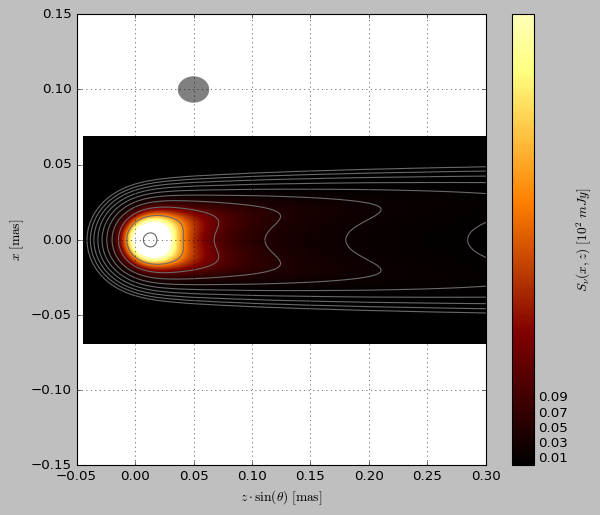

In [ ]:
from matplotlib.patches import Ellipse
# nice_fonts = {
#         # Use LaTeX to write all text
#         "text.usetex": False,
#         "font.family": 'serif',
#         # Use 10pt font in plots, to match 10pt font in document
#         "axes.labelsize": 16,
#         "font.size": 16,
#         "axes.linewidth":1,
#         "axes.titlesize":20,
#         # Make the legend/label fonts a little smaller
#         "legend.fontsize": 10,
#         "xtick.labelsize": 14,
#         "ytick.labelsize": 14,
# }
# matplotlib.rcParams.update(nice_fonts)

#plt.clf()
with plt.style.context(('classic')):
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    ax.set_xlim([-0.05, .30])
    ax.set_ylim([-0.15, 0.15])
    palette = plt.cm.afmhot
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    ticks = [0.01,0.03,0.05,0.07,0.09]#[0.01, 0.05,  0.1,  0.15]
    norm = matplotlib.colors.Normalize(vmin=0, vmax=0.7)
    CS_conv = ax.contourf(Y_c, X_c, I_c/1e2, cmap=palette, norm=norm, levels=np.linspace(0,0.6, 500))
    # ticks = [0.001,0.01,0.1,1,10,100,1000,10000,1e5]#[0.01, 0.05,  0.1,  0.15]
    # norm = matplotlib.colors.LogNorm(vmin=1e1, vmax=I_c.max())
    # CS_conv = ax.contourf(Y_c, X_c, I_c, cmap=palette, norm=norm, levels=np.geomspace(0.01,1e3, 500))

    #Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1 --> son 19? aprox
    # obs_cont = np.linspace(0.01,1.1,10)
    obs_cont = np.geomspace(0.01,1e2,10)
    plot_cont = ax.contour(Y_c, X_c, (I_c), linewidths=1, levels=obs_cont, extend="both", colors='dimgrey')

    el = Ellipse((0.05,0.1), FWHM_y, FWHM_x, color='grey')
    ax.add_patch(el)

    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$S_\nu(x,z)~[10^2~mJy]$')
    
    plt.savefig('Gaussian_Convolved_Map(1).png', dpi=300)

# Pruebas de convolucion

In [22]:
z, _, r_out, _, _ = get_z_rz()
z = np.linspace(z.min(), z.max(), 200)
x = np.linspace(-r_out.max(), r_out.max(), 200)
I_puntual = np.zeros((len(z), len(x)))

In [23]:
# I_puntual[100,100]=2e-3
I_puntual[88,100]=1
I_puntual[113,100]=1
FWHM=0.05
sigma_x=FWHM/(2*np.sqrt(2*np.log(2)))
sigma_y=FWHM/(2*np.sqrt(2*np.log(2)))
# sigma_x=1/(2*np.sqrt(2*np.log(2)))
# sigma_y=1/(2*np.sqrt(2*np.log(2)))
X_c, Y_c, I_puntual_c = Convolve_map(X_m[0]*convert, Z_m.T[0]*np.sin(incl)*convert, I_puntual.T, sigma_x, sigma_y)

200 -0.04750459288707559 0.04750459288707559
1.0
0.22240745581735405 1.2316383786161058
Numero de celdas del mapa convolucionado:
69 386
-0.08471978274563358
Dimension of the convolution grid: 69x386


KeyboardInterrupt: 

In [ ]:
# I_puntual_c.max()

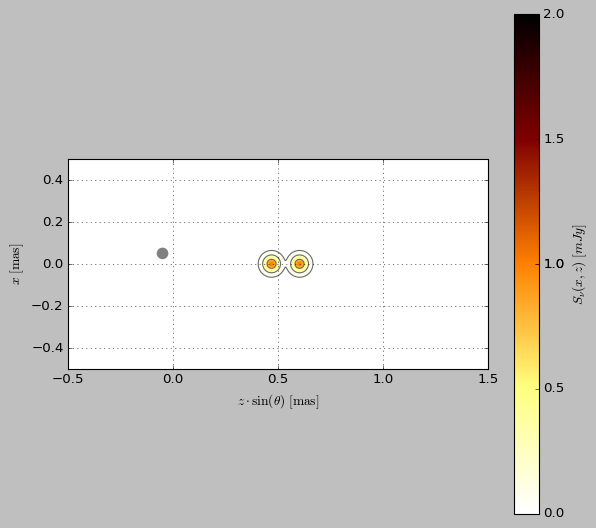

In [ ]:
from matplotlib.patches import Ellipse
with plt.style.context(('classic')):
    
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    ax.set_aspect('equal', adjustable='box')
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    ax.set_xlim([-0.5,1.5])
    ax.set_ylim([-0.5, 0.5])
    palette = plt.cm.afmhot_r
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    ticks = [0, 0.5,1,I_puntual_c.max(),1.5,2]#[0.01, 0.05,  0.1,  0.15]
    norm = matplotlib.colors.Normalize(vmin=0, vmax=2)
    CS_conv = ax.contourf(Y_c, X_c, I_puntual_c, cmap=palette, norm=norm, levels=np.linspace(0,2, 500))
    # # ticks = [0.001,0.01,0.1,1,10,100,1000,10000,1e5]#[0.01, 0.05,  0.1,  0.15]
    # norm = matplotlib.colors.LogNorm(vmin=1e-3, vmax=I_puntual_c.max())
    # CS_conv = ax.contourf(Y_c, X_c, I_puntual_c, cmap=palette, norm=norm, levels=np.geomspace(1e-3,5 e4, 500))

    #Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1 --> son 19? aprox
    # # obs_cont = np.linspace(0.01,1.1,10)
    obs_cont = [0.0111*I_puntual_c.max(), 0.1353*I_puntual_c.max(), 0.6065*I_puntual_c.max()]
    plot_cont = ax.contour(Y_c, X_c, (I_puntual_c), linewidths=1, levels=obs_cont, extend="both", colors='dimgrey')

    el = Ellipse((-FWHM,FWHM), FWHM, FWHM, color='grey')
    ax.add_patch(el)

    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$S_\nu(x,z)~[mJy]$')
    plt.savefig(fr'Gaussian_Convolved_Map({sigma_x*(2*np.sqrt(2*np.log(2)))}).png', dpi=300)


In [ ]:
def Omega_beam(theta1, theta2):
    '''Beam solid angle in terms of the theta_HPBW (theta1 x theta2)
    Use the equation here: https://science.nrao.edu/facilities/vla/proposing/TBconv'''
    return np.pi * theta1 * theta2 / (4 * np.log(2))


In [ ]:
def brightness_temperature(I, nu_hz):
    """
    Calculate the brightness temperature for a given intensity and frequency.

    Parameters:
    I (float or numpy.ndarray): Specific intensity [erg/s/cm^2/Hz].
    nu (float): Frequency [Hz].

    Returns:
    float or numpy.ndarray: Brightness temperature [K].
    """
    nu_hz *= 1e9 # Convert GHz to Hz
    

    return (c**2 * I) / (2 * k_B * nu_hz**2*Omega_beam(np.deg2rad(23 * 1e-3 / 3600),np.deg2rad(45 * 1e-3 / 3600))) #[K]

In [ ]:
T_brillo=brightness_temperature(I_puntual_c, 230.0)

In [ ]:
T_brillo.max()

np.float64(2.231960069590674e+27)

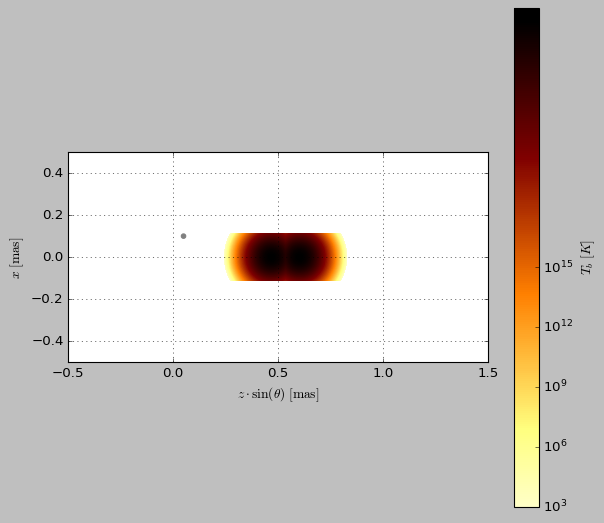

In [ ]:
with plt.style.context(('classic')):
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    ax.set_aspect('equal', adjustable='box')
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    ax.set_xlim([-0.5, 1.5])
    ax.set_ylim([-0.5, 0.5])
    palette = plt.cm.afmhot_r
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    # ticks = [0.1, 0.5, 0.9,1.1]#[0.01, 0.05,  0.1,  0.15]
    # norm = matplotlib.colors.Normalize(vmin=0, vmax=I_c.max()/1e2)
    # CS_conv = ax.contourf(Y_c, X_c, I_c/1e2, cmap=palette, norm=norm, levels=np.linspace(0,1.1, 500))
    ticks = [1e3,1e6,1e9,1e12,1e15]#[0.01, 0.05,  0.1,  0.15]
    norm = matplotlib.colors.LogNorm(vmin=1e0, vmax=T_brillo.max())
    CS_conv = ax.contourf(Y_c, X_c, T_brillo, cmap=palette, norm=norm, levels=np.geomspace(1e3,1e28, 500))

    #Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1 --> son 19? aprox
    # # obs_cont = np.linspace(0.01,1.1,10)
    # obs_cont = np.geomspace(0.01,1e2,10)
    # plot_cont = ax.contour(Y_c, X_c, (I_c), linewidths=1, levels=obs_cont, extend="both", colors='dimgrey')

    el = Ellipse((0.05,0.1), sigma_y, sigma_x, color='grey')
    ax.add_patch(el)

    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$T_b~[K]$')


## ---------------------------------------------------------------------------------

In [ ]:
T_brillo=brightness_temperature(I.T, 230.0)
X_c, Y_c, T_b = Convolve_map(X_m[0]*convert, Z_m.T[0]*np.sin(incl)*convert, T_brillo, sigma_x, sigma_y)

200 -0.04750459288707559 0.04750459288707559
0.13781500450866735 1.1497637570683408
Numero de celdas del mapa convolucionado:
128 696
-0.04378247197175105
Dimension of the convolution grid: 128x696
Pre-conv: S(GHz) = 5514552446934.348 mJy
Post-conv: S(GHz) = 5423372709078.684 mJy
post/pre = 0.983465614166685


In [ ]:
T_brillo=brightness_temperature(I.T, 230.0)
f"{T_brillo.max()/1e9:.2e}"
# f"{np.sqrt(T_brillo.max()/1e9):.2e}"
# np.sqrt(T_brillo.max()/1e9)
T_brillo.max()/1e9

np.float64(22.246714984322885)

In [ ]:
T_brillo[T_brillo == 0] = -99

In [ ]:
T_b.max()/1e12

np.float64(1.6045674941192143)

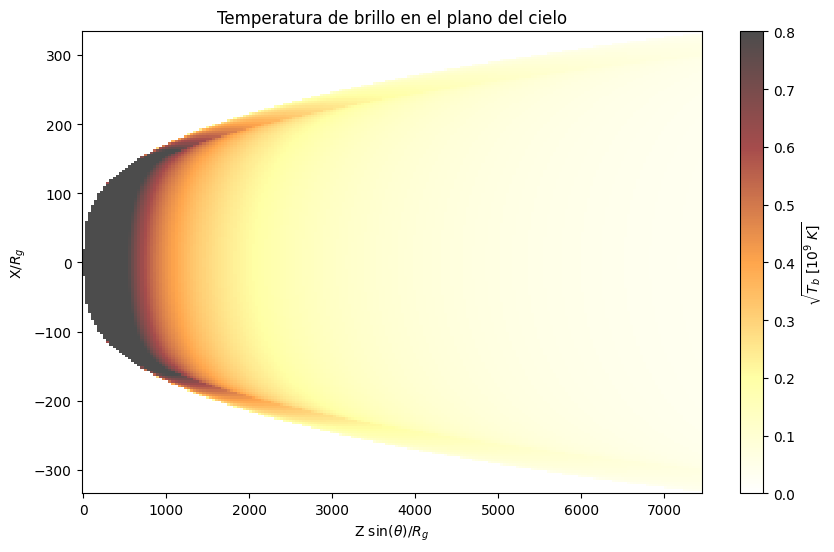

In [ ]:
# Plotting
palette = plt.cm.afmhot_r
plt.figure(figsize=(10, 6))
norm = matplotlib.colors.Normalize(vmin=0, vmax=0.8)#np.sqrt(T_brillo.max()/1e9))
plt.pcolormesh(Z_m * np.sin(incl)/R_g, X_m/R_g, np.sqrt(T_brillo.T/1e9), cmap=palette, norm=norm, alpha=0.7)
#plt.pcolormesh(Z_m * np.sin(incl)/R_g, -X_m/R_g, I, cmap=palette, norm=norm, alpha=0.7)
#plt.pcolormesh(Z_m * np.sin(incl) * convert, X_m * convert, I, cmap=palette, alpha=0.7)
plt.colorbar(label=r'$\sqrt{T_b~[10^9~K]}$')
plt.xlabel(r'Z $\sin(\theta)$/$R_g$')
plt.ylabel(r'X/$R_g$')
#plt.xlim(0,100000)
plt.title(r'Temperatura de brillo en el plano del cielo')
plt.show()

In [ ]:
np.sqrt(T_b.max() / 1e9)
# np.sqrt(T_b.min() / 1e9)

np.float64(2.580429033605728e-10)

ValueError: vmin must be less or equal to vmax

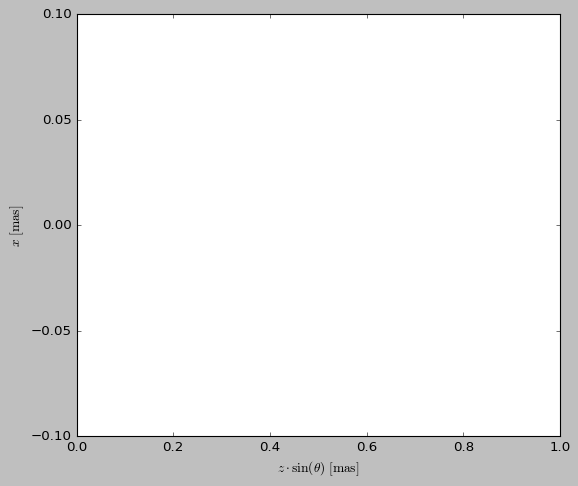

In [ ]:
with plt.style.context(('classic')):
    fig, ax = plt.subplots(1, 1, figsize=(7.8, 6.6)) # proportion: 2.6/2.2
    #fig, ax = plt.subplots(1, 1) 
    ax.set_xlabel(r"$z\cdot\sin(\theta)~{\rm [mas]}$")
    ax.set_ylabel(r"$x~{\rm [mas]}$")
    #ax.set_xlim([-0.9, 1.7])
    ax.set_ylim([-0.1, 0.1])
    palette = plt.cm.afmhot_r
    #cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
    ticks = [0,10,20,30,40,50]  # Adjusted ticks for sqrt(T_b) in Gigakelvin
    norm = matplotlib.colors.LogNorm(vmin=0.001, vmax=np.sqrt(T_b.max()/1e9))
    CS_conv = ax.contourf(Y_c, X_c, np.sqrt(T_b/1e9), cmap=palette, norm=norm, levels=np.logspace(-1,2 , 700))

    #Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1 --> son 19? aprox
    obs_cont = np.array([-1,-0.5,0,0.5,1,2])
    plot_cont = ax.contour(Y_c, X_c, np.sqrt(T_b/1e9), linewidths=1, levels=obs_cont, extend="both", colors=['dimgrey'])

    el = Ellipse((0.0, 0.075), sigma_y, sigma_x, color='grey')
    ax.add_patch(el)

    ax.grid()
    plt.tight_layout()
    fig.colorbar( CS_conv, ticks=ticks ,label=r'$\sqrt{T_b~[10^9~K]}$')
    
    #plt.savefig('Gaussian_Convolved_Map(1).png', dpi=300)

In [ ]:
T_b_df = pd.DataFrame(T_b, index=X_c, columns=Y_c)
T_b_df.index.name = 'X_c'
T_b_df.columns.name = 'Y_c'

In [ ]:
# Calculate the average over each column
T_b_xplus=T_b_df[T_b_df.index > 0]
T_b_xminus=T_b_df[T_b_df.index < 0]

In [ ]:
z, _, _, r_in, _ = get_z_rz()
Inner_Radius_z=interp1d(safe_log(z), safe_log(r_in), bounds_error=False, fill_value='extrapolate')
T_b_abs_columns = abs(Y_c)
r_in_values = np.exp(Inner_Radius_z(safe_log(T_b_abs_columns/convert/np.sin(incl))))
r_in_values *=convert
Bright_Temp = np.zeros(len(Y_c))
for i, value in enumerate(r_in_values):
    closest_index = T_b_xplus.index.get_indexer([value], method='nearest')[0]
    Bright_Temp[i]=T_b_xplus.iloc[closest_index, T_b_xplus.columns.get_loc(Y_c[i])]

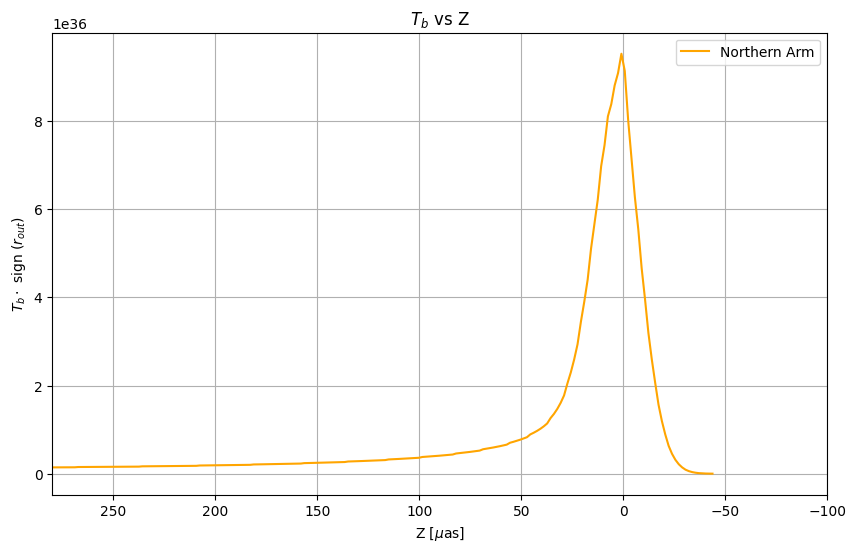

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(Y_c*1e3, Bright_Temp, label='Northern Arm', color='orange')
#plt.plot(Y_c*1e3, -T_b_df.loc['Average_-'], label='Southern Arm', color='blue')
plt.gca().invert_xaxis()
plt.xlim(280,-100)
plt.xlabel(r'Z [$\mu$as]')
plt.ylabel(r'$T_b \cdot$ sign $(r_{out})$')
plt.title(r'$T_b$ vs Z')
plt.legend()
plt.grid()
plt.show()